# Liczenie wskaźników kompresji JPEG dla wielu obrazów i zapisywanie wyników do pliku CSV

In [10]:
import os
import cv2
import pandas as pd
from index_script import detect_jpeg_blockiness, detect_jpeg_compression

IMAGE_FILES_DIR = "web-cam-images"
CSV_RESULTS_FILE = "multiple-compression-results/compression_analysis_results.csv"

# Get all files in the multiple-compression directory
image_files = [os.path.join(IMAGE_FILES_DIR, f) for f in os.listdir(IMAGE_FILES_DIR) if os.path.isfile(os.path.join(IMAGE_FILES_DIR, f)) and f.lower().endswith(('.jpg', '.jpeg', '.png', '.ppm'))]

# Initialize lists to store metrics
results = []

# Process each image file
for image_path in image_files:
    print(f"\nAnalyzing: {image_path}")
    try:
        # Calculate all metrics using detect_jpeg_compression
        compression_result = detect_jpeg_compression(image_path)
        
        # Store results with filename
        result_dict = {
            'filename': os.path.basename(image_path),
            **compression_result  # Unpack all metrics from detect_jpeg_compression
        }
        
        results.append(result_dict)
        
    except Exception as e:
        print(f"Error processing {image_path}: {e}")

print(f"\nProcessed {len(results)} images successfully")

# Save results to CSV
df = pd.DataFrame(results)
df.to_csv(CSV_RESULTS_FILE, index=False)



Analyzing: web-cam-images\direct_camera_shot_cam0.png

Analyzing: web-cam-images\direct_camera_shot_cam1.png

Analyzing: web-cam-images\loaded_camera_shot.png

Analyzing: web-cam-images\zdjecie_zrobione_przez_aparat(klik).jpg

Processed 4 images successfully


In [7]:
df.head()

,filename,energy_mean,energy_std,estimated_quality,psnr,blockiness_mean,blockiness_max,blockiness_std,blockiness_0,blockiness_1,blockiness_2,blockiness_3,blockiness_4,blockiness_5,blockiness_6,blockiness_7
0,direct_camera_shot_cam0.png,82.668221,137.885666,92,60.660096,1.001356,1.192660,0.109528,1.178847,1.192660,1.002385,0.941962,0.918829,0.925821,0.914740,0.935605
1,direct_camera_shot_cam1.png,137.637299,356.042572,95,49.875926,1.000022,1.013490,0.009679,0.994190,0.988889,1.013490,1.008702,1.007848,0.993264,0.986693,1.007102
2,loaded_camera_shot.png,137.637299,356.042572,95,49.875926,1.000022,1.013490,0.009679,0.994190,0.988889,1.013490,1.008702,1.007848,0.993264,0.986693,1.007102
3,zdjecie_zrobione_przez_aparat(klik).jpg,35.440636,94.411736,90,74.281942,1.000716,1.170763,0.073349,0.924749,1.013077,0.979422,0.991380,0.991571,1.019122,0.915644,1.170763


# Wizualizacje

In [23]:
# Wczytanie danych

# CSV_FILE_PATH = 'multiple-compression-results/compression_analysis_results.csv'
CSV_FILE_PATH = 'results_ppm.csv'

df_file = pd.read_csv(CSV_FILE_PATH)

print(f"Wymiary DataFrame: {df_file.shape}")
df_file.head()

Wymiary DataFrame: (11338, 17)


,filename,extension,blockiness_0,blockiness_1,blockiness_2,blockiness_3,blockiness_4,blockiness_5,blockiness_6,blockiness_7,blockiness_max,blockiness_mean,blockiness_std,energy_mean,energy_std,estimated_quality,psnr
0,00001_930831_fa_a,.ppm,0.993078,1.001009,0.999691,1.010075,0.989684,1.005070,1.001917,0.999495,1.010075,1.000002,0.005985,289.520630,274.786316,95,43.797279
1,00001_930831_fb_a,.ppm,1.007297,1.003596,0.995729,1.011908,0.990728,0.996879,0.997464,0.996393,1.011908,0.999999,0.006532,286.008270,278.255157,95,43.886630
2,00001_930831_hl_a,.ppm,1.002037,1.001553,0.999654,1.004157,0.996359,0.999376,0.995875,1.000986,1.004157,1.000000,0.002636,298.347534,262.925873,95,43.718977
3,00001_930831_hr_a,.ppm,0.998311,0.997910,0.998912,0.998156,1.000133,0.993450,1.003732,1.009520,1.009520,1.000015,0.004462,302.434540,271.724670,95,43.725833
4,00001_930831_pr_a,.ppm,0.994717,1.005770,1.009800,0.995494,0.992281,0.997842,1.002282,1.001870,1.009800,1.000007,0.005596,238.877945,215.813538,95,44.249746


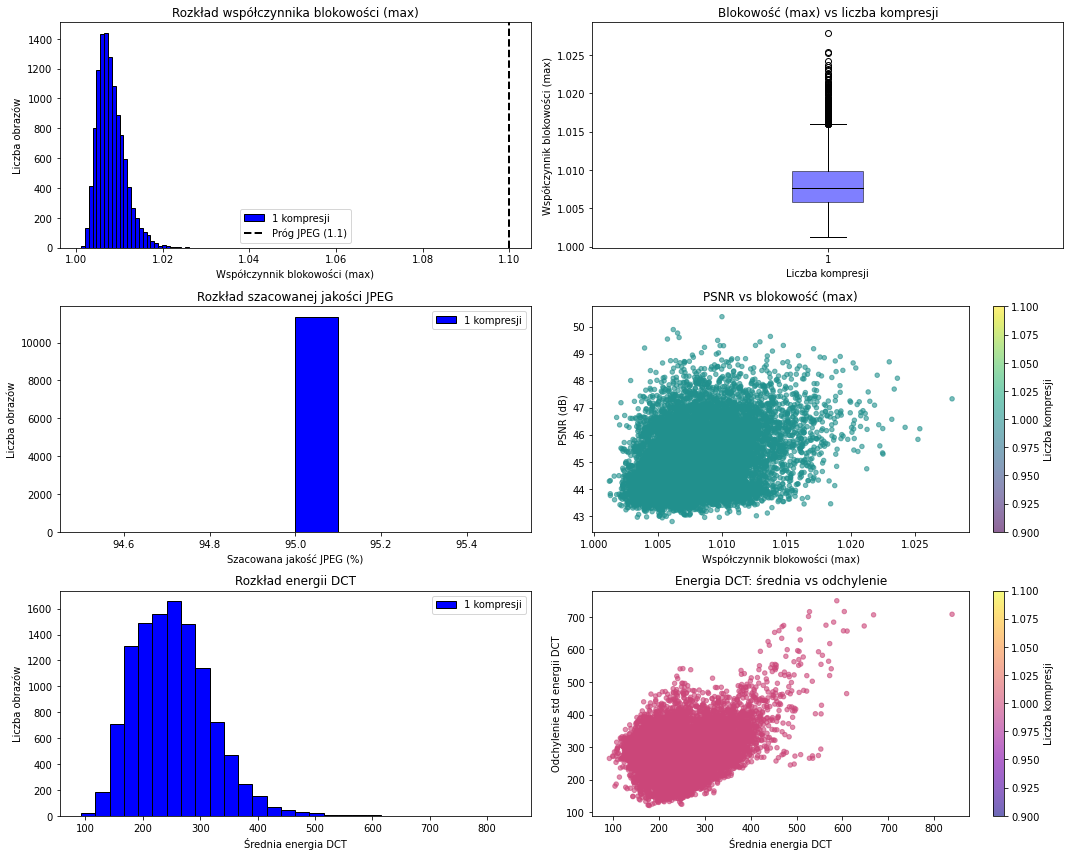

In [28]:
# Tworzenie wykresów i histogramów na podstawie wyników analizy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Konwertuj wyniki do DataFrame dla łatwiejszej analizy
results_df = df_file

# Dodaj kolumnę z informacją o liczbie kompresji (na podstawie nazwy pliku)
def get_compression_count(filename):
    # Zlicz wystąpienia '.q' w nazwie pliku
    q_count = filename.count('.q')
    
    if filename.endswith('.png') or filename.endswith('.ppm'):
        return 0  # Brak kompresji JPEG
    elif q_count == 0:
        return 1  # Pojedyncza kompresja (np. _q10.jpg)
    else:
        return q_count + 1  # Liczba '.q' + 1 = całkowita liczba kompresji

results_df['compression_count'] = results_df['filename'].apply(get_compression_count)

# Stwórz figurę z wieloma wykresami
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# Kolory dla różnych poziomów kompresji
colors = ['blue', 'green', 'orange', 'red']
compression_levels = sorted(results_df['compression_count'].unique())

# 1. Histogram współczynnika blokowości (max) z podziałem na liczbę kompresji (stacked)
data_blockiness = [results_df[results_df['compression_count'] == comp]['blockiness_max'].values 
                   for comp in compression_levels]
axes[0, 0].hist(data_blockiness, bins=30, label=[f'{comp} kompresji' for comp in compression_levels], 
                color=colors[:len(compression_levels)], edgecolor='black', stacked=True)
axes[0, 0].set_xlabel('Współczynnik blokowości (max)')
axes[0, 0].set_ylabel('Liczba obrazów')
axes[0, 0].set_title('Rozkład współczynnika blokowości (max)')
axes[0, 0].axvline(1.1, color='black', linestyle='--', linewidth=2, label='Próg JPEG (1.1)')
axes[0, 0].legend()

# 2. Boxplot współczynnika blokowości według liczby kompresji
compression_groups = results_df.groupby('compression_count')['blockiness_max'].apply(list)
bp = axes[0, 1].boxplot(compression_groups.values, labels=compression_groups.index, patch_artist=True)
for patch, color in zip(bp['boxes'], colors[:len(compression_groups)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
# Zmień kolor linii mediany na czarny
for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(1)
axes[0, 1].set_xlabel('Liczba kompresji')
axes[0, 1].set_ylabel('Współczynnik blokowości (max)')
axes[0, 1].set_title('Blokowość (max) vs liczba kompresji')

# 3. Histogram szacowanej jakości JPEG z podziałem na liczbę kompresji (stacked)
data_quality = [results_df[results_df['compression_count'] == comp]['estimated_quality'].values 
                for comp in compression_levels]
axes[1, 0].hist(data_quality, bins=10, label=[f'{comp} kompresji' for comp in compression_levels],
                color=colors[:len(compression_levels)], edgecolor='black', stacked=True)
axes[1, 0].set_xlabel('Szacowana jakość JPEG (%)')
axes[1, 0].set_ylabel('Liczba obrazów')
axes[1, 0].set_title('Rozkład szacowanej jakości JPEG')
axes[1, 0].legend()

# 4. Scatter plot: PSNR vs współczynnik blokowości
scatter = axes[1, 1].scatter(results_df['blockiness_max'], results_df['psnr'], 
                             c=results_df['compression_count'], cmap='viridis', alpha=0.6, s=20)
axes[1, 1].set_xlabel('Współczynnik blokowości (max)')
axes[1, 1].set_ylabel('PSNR (dB)')
axes[1, 1].set_title('PSNR vs blokowość (max)')
plt.colorbar(scatter, ax=axes[1, 1], label='Liczba kompresji')

# 5. Histogram energii DCT z podziałem na liczbę kompresji (stacked)
data_energy = [results_df[results_df['compression_count'] == comp]['energy_mean'].values 
               for comp in compression_levels]
axes[2, 0].hist(data_energy, bins=30, label=[f'{comp} kompresji' for comp in compression_levels],
                color=colors[:len(compression_levels)], edgecolor='black', stacked=True)
axes[2, 0].set_xlabel('Średnia energia DCT')
axes[2, 0].set_ylabel('Liczba obrazów')
axes[2, 0].set_title('Rozkład energii DCT')
axes[2, 0].legend()

# 6. Scatter plot: Energia DCT vs odchylenie
scatter2 = axes[2, 1].scatter(results_df['energy_mean'], results_df['energy_std'], 
                              c=results_df['compression_count'], cmap='plasma', alpha=0.6, s=20)
axes[2, 1].set_xlabel('Średnia energia DCT')
axes[2, 1].set_ylabel('Odchylenie std energii DCT')
axes[2, 1].set_title('Energia DCT: średnia vs odchylenie')
plt.colorbar(scatter2, ax=axes[2, 1], label='Liczba kompresji')

plt.tight_layout()
plt.show()